# 模拟 Fintech 月度经营分析包（预算差异 × 13 周现金流 × 三情景 × 融资建议）

**业务问题**：一家增长期消费信贷平台（模拟：星链数科）利润刚转正、但放款本金净投放使经营现金流持续为负——月度经营分析包要回答四个问题：

```
最新月预算差异在哪（量 or 价）→ 未来 13 周现金何时见底
   → 三情景下盈利能力走向 → 要不要融资、融多少、什么时候到位
```

**口径声明**
- 数据为**固定种子模拟**（`src/finance.simulate_company`，seed=42），非真实公司；金额单位万元；
- 流动性口径（13 周现金流，含放款本金净投放）与损益口径（三情景，经营利润）分开报告；
- 全部产出为分析底稿，不构成投资建议；数字需人工复核签署后使用。

月度损益 24 个月（2023-01 ~ 2024-12）| 周度现金流 52 周 | 期初现金 ¥4500 万

收入 ¥100.2 → ¥188.7 万/月；经营利润 ¥-7.0 → ¥22.1 万/月（9 负 14 正，2024-06 风险事件月 ¥-8.7 万）


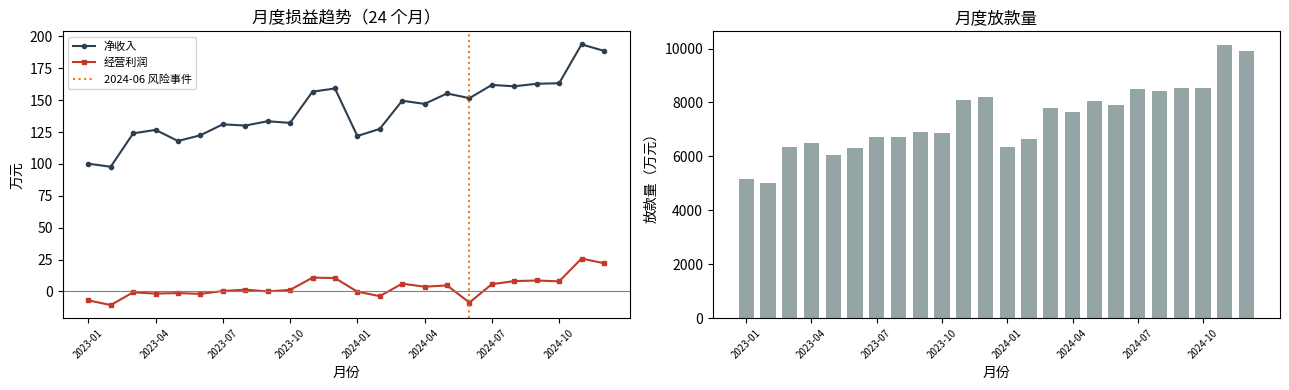

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import finance as fin  # noqa: E402

plt.rcParams.update({"font.sans-serif": ["Noto Sans CJK JP", "DejaVu Sans"], "axes.unicode_minus": False})

monthly, weekly, OPEN_CASH = fin.simulate_company(seed=SEED)  # 固定种子模拟：P4 演示完整方法论链路，真实账本不可公开；seed=42 保证任何人复跑得到逐位一致的数据与结论
print("月度损益 %d 个月（%s ~ %s）| 周度现金流 %d 周 | 期初现金 ¥%.0f 万"
      % (len(monthly), monthly.month.iloc[0], monthly.month.iloc[-1], len(weekly), OPEN_CASH))
print("\n收入 ¥%.1f → ¥%.1f 万/月；经营利润 ¥%.1f → ¥%.1f 万/月（%d 负 %d 正，2024-06 风险事件月 ¥%.1f 万）"
      % (monthly.revenue.iloc[0], monthly.revenue.iloc[-1], monthly.op_profit.iloc[0],
         monthly.op_profit.iloc[-1], (monthly.op_profit < 0).sum(), (monthly.op_profit > 0).sum(),
         monthly.op_profit[17]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(len(monthly)), monthly.revenue, "o-", ms=3, c="#2c3e50", label="净收入")
axes[0].plot(range(len(monthly)), monthly.op_profit, "s-", ms=3, c="#c0392b", label="经营利润")
axes[0].axhline(0, c="grey", lw=.8); axes[0].axvline(17, ls=":", c="#e67e22", label="2024-06 风险事件")
axes[0].set(xlabel="月份", ylabel="万元", title="月度损益趋势（24 个月）"); axes[0].legend(fontsize=8)
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_xticklabels(monthly.month[::3], rotation=45, fontsize=7)
axes[1].bar(range(len(monthly)), monthly.volume, color="#95a5a6", width=.7)
axes[1].set(xlabel="月份", ylabel="放款量（万元）", title="月度放款量")
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xticklabels(monthly.month[::3], rotation=45, fontsize=7)
fig.tight_layout(); fig.savefig(ROOT / "images/monthly_trend.png", dpi=150); plt.show()

## 1. 最新月预算差异：中值法量价分解

收入 = 放款量 × 净收入率，两因子差异用**中值法**分解（价差、量差各按两端中值加权，归因不冲突、无需规定先后顺序）：

```
价差 = (P实际 − P预算) × (Q实际 + Q预算) / 2        量差 = (Q实际 − Q预算) × (P实际 + P预算) / 2
```

最新月背景：放款量超目标 5%，但净收入率低于预算 0.02pp——**"以价换量"**，差异分解要能指出利润是量补来的还是价丢的。

最新月 2024-12：预算收入 ¥181.6 vs 实际收入 ¥188.7（差异 ¥+7.1）
  价差 ¥-1.9（净收入率 1.91% vs 预算 1.93%）| 量差 ¥+9.0（放款 9902 vs 预算 9430 万）


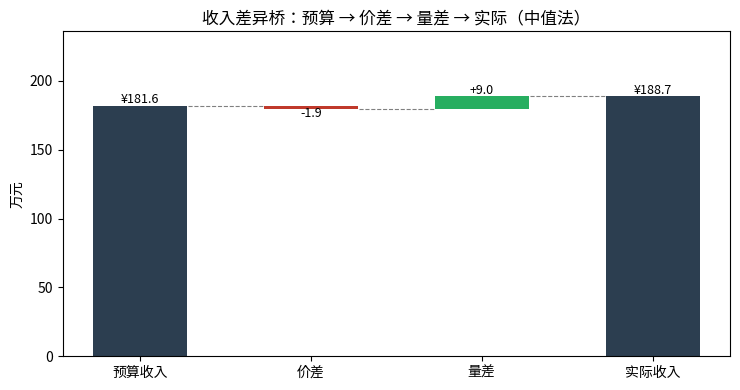

In [2]:
last = monthly.iloc[-1]
rev_a = last.nim * last.volume          # 未舍入实际收入，保证差异桥恒等
rev_b = last.budget_nim * last.budget_volume
var = fin.pv_variance(last.budget_nim, last.budget_volume, last.nim, last.volume)  # 中值法而非"先量后价"：价差/量差各按两端中值加权，归因不冲突、无顺序依赖，恒等式 价差+量差=总差异 可断言校验（见下方 assert）
print("最新月 %s：预算收入 ¥%.1f vs 实际收入 ¥%.1f（差异 ¥%+.1f）"
      % (last.month, rev_b, rev_a, var["total"]))
print("  价差 ¥%+.1f（净收入率 %.2f%% vs 预算 %.2f%%）| 量差 ¥%+.1f（放款 %.0f vs 预算 %.0f 万）"
      % (var["price_effect"], 100 * last.nim, 100 * last.budget_nim,
         var["volume_effect"], last.volume, last.budget_volume))
assert abs(var["total"] - (rev_a - rev_b)) < 1e-6, "中值法恒等式校验失败"

bridge = pd.DataFrame([
    {"项目": "预算收入", "值": rev_b, "类型": "total"},
    {"项目": "价差", "值": var["price_effect"], "类型": "delta"},
    {"项目": "量差", "值": var["volume_effect"], "类型": "delta"},
    {"项目": "实际收入", "值": rev_a, "类型": "total"},
])
fig, ax = plt.subplots(figsize=(7.5, 4))
cum = 0.0
for i, r in bridge.iterrows():
    if r["类型"] == "total":
        ax.bar(i, r["值"], color="#2c3e50", width=.55); cum = r["值"]
        ax.text(i, r["值"] + 2, "¥%.1f" % r["值"], ha="center", fontsize=9)
    else:
        ax.bar(i, r["值"], bottom=cum, color="#27ae60" if r["值"] > 0 else "#c0392b", width=.55)
        ax.text(i, cum + r["值"] + (2 if r["值"] > 0 else -6), "%+.1f" % r["值"], ha="center", fontsize=9)
        cum += r["值"]
    if i < len(bridge) - 1:
        ax.plot([i + .28, i + 1 - .28], [cum, cum], ls="--", c="grey", lw=.8)
ax.set_xticks(range(len(bridge))); ax.set_xticklabels(bridge["项目"])
ax.set(ylabel="万元", title="收入差异桥：预算 → 价差 → 量差 → 实际（中值法）")
ax.set_ylim(0, rev_a * 1.25)
fig.tight_layout(); fig.savefig(ROOT / "images/variance_bridge.png", dpi=150); plt.show()

## 2. 13 周现金流预测（流动性口径）

增长期平台放款本金净投放（回收系数 0.92 < 1），经营现金流结构性为负。用 **Holt 线性指数平滑**（网格搜索 α/β 最小化历史 SSE）预测未来 13 周净现金流，按残差 σ 给 **80% 预测区间**（随机游走近似：区间宽度随提前期 √h 扩大），滚动到期初现金得到**现金余额跑道**。

- 缓冲线：¥3,000 万（约 6 周净流出 + 月度运营支出）；
- 关注三个数：**缓冲线击穿周**、**最低现金周**、**融资缺口**。

Holt（α=0.1, β=0.25，残差 σ=107）：预测周净现金流 ¥-274 → ¥-406
现金跑道：期初 ¥4500 → 第 6 周击穿缓冲 ¥3000 → 第 13 周见底 ¥80；80% 悲观边界第 13 周 ¥-4434
融资缺口 = max(0, 缓冲 − 最低现金) = ¥2920 万


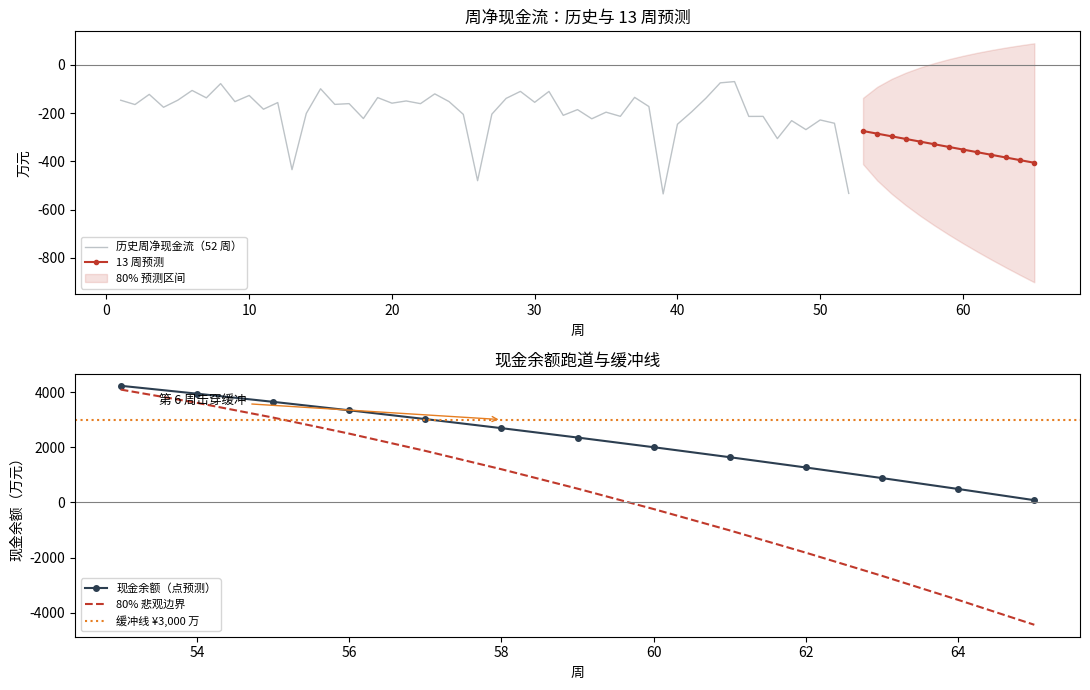

In [3]:
point, resid, alpha, beta = fin.fit_holt(weekly.net_cf.values, h=13)  # Holt 线性指数平滑（网格搜 α/β）：周度现金流无外生驱动，参数少、可解释；80% 区间=1.2816σ√h（随机游走近似），随提前期扩大，回答"最坏要准备多少"
lo, hi = fin.forecast_band(point, resid.std(ddof=1))
bal = fin.cash_runway(point, OPEN_CASH)              # 第 0-13 周现金余额
bal_lo = fin.cash_runway(lo, OPEN_CASH)              # 80% 悲观边界
BUFFER = 3000.0
breach = int(np.argmax(bal < BUFFER))                # 首个低于缓冲线的周（0=期初）
gap = fin.funding_gap(bal.min(), BUFFER)
print("Holt（α=%.1f, β=%.2f，残差 σ=%.0f）：预测周净现金流 ¥%.0f → ¥%.0f"
      % (alpha, beta, resid.std(ddof=1), point[0], point[-1]))
print("现金跑道：期初 ¥%.0f → 第 %d 周击穿缓冲 ¥%.0f → 第 13 周见底 ¥%.0f；80%% 悲观边界第 13 周 ¥%.0f"
      % (bal[0], breach, BUFFER, bal[-1], bal_lo[-1]))
print("融资缺口 = max(0, 缓冲 − 最低现金) = ¥%.0f 万" % gap)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
axes[0].plot(weekly.week, weekly.net_cf, c="#bdc3c7", lw=1, label="历史周净现金流（52 周）")
axes[0].plot(np.arange(53, 66), point, "o-", ms=3, c="#c0392b", label="13 周预测")
axes[0].fill_between(np.arange(53, 66), lo, hi, color="#c0392b", alpha=.15, label="80% 预测区间")
axes[0].axhline(0, c="grey", lw=.8)
axes[0].set(xlabel="周", ylabel="万元", title="周净现金流：历史与 13 周预测"); axes[0].legend(fontsize=8)
axes[1].plot(np.arange(53, 66), bal[1:], "o-", ms=4, c="#2c3e50", label="现金余额（点预测）")
axes[1].plot(np.arange(53, 66), bal_lo[1:], ls="--", c="#c0392b", label="80% 悲观边界")
axes[1].axhline(BUFFER, ls=":", c="#e67e22", label="缓冲线 ¥3,000 万")
axes[1].axhline(0, c="grey", lw=.8)
axes[1].annotate("第 %d 周击穿缓冲" % breach, xy=(52 + breach, BUFFER),
                 xytext=(52 + breach - 4.5, BUFFER + 550), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color="#e67e22"))
axes[1].set(xlabel="周", ylabel="现金余额（万元）", title="现金余额跑道与缓冲线"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(ROOT / "images/cash_forecast.png", dpi=150); plt.show()

## 3. 三情景损益前瞻（盈利口径）

从基准月出发外推 12 个月，对四个驱动施加情景乘数：**放款量增速、净收入率、获客成本率、信用损失率**。损益口径不含放款本金的营运现金净投放（流动性由模块 2 覆盖）——这是 FP&A 的标准分工。

| 情景 | 放款月增 | 净收入率 | 获客成本 | 信用损失 | 含义 |
|---|---|---|---|---|---|
| Base | 1.5% | 持平 | 持平 | 持平 | 延续当前趋势 |
| Bull | 2.5% | +5% | −10% | −15% | 客群上移、风控改善 |
| Bear | 0.5% | −8% | +10% | +30% | 宏观恶化、风险抬头 |

      情景  12个月收入合计  经营利润合计   利润率  年末月利润
Base（基准）    2498.3   337.2  0.13   33.6
Bull（乐观）    2802.1   724.1  0.26   74.8
Bear（悲观）    2152.5  -179.4 -0.08  -15.0


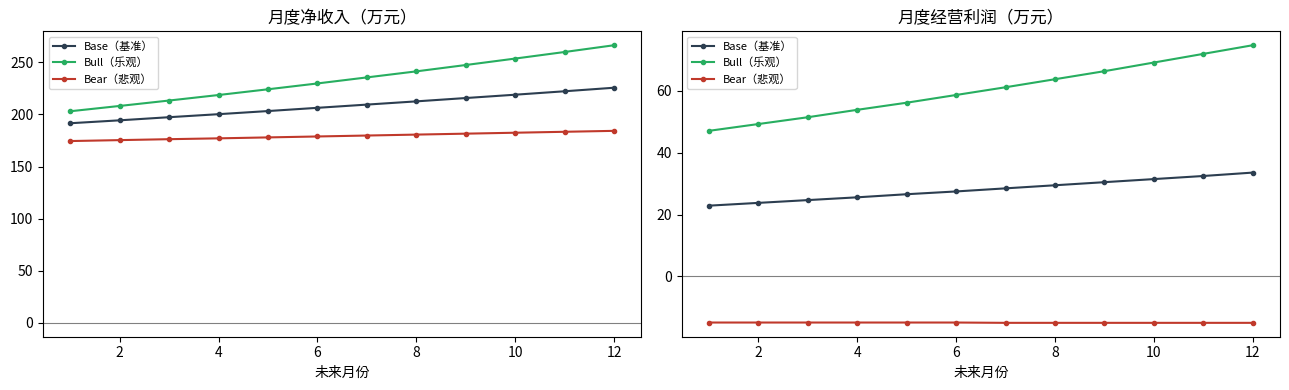

In [4]:
scen_defs = {  # 三情景乘数是业务/风险/财务的前瞻假设（主观但需三方联审）：情景度量经营韧性，非资本配置建议；上线后以滚动重估校准
    "Base（基准）": dict(g_q=0.015, mults=dict(volume=1.00, nim=1.00, cac=1.00, loss=1.00)),
    "Bull（乐观）": dict(g_q=0.025, mults=dict(volume=1.00, nim=1.05, cac=0.90, loss=0.85)),
    "Bear（悲观）": dict(g_q=0.005, mults=dict(volume=1.00, nim=0.92, cac=1.10, loss=1.30)),
}
scen = {k: fin.scenario_pl(last.volume, last.nim, last.acquisition / last.volume,
                           last.credit_loss / last.volume, last.opex, **v)
        for k, v in scen_defs.items()}
summ = pd.DataFrame([{"情景": k, "12个月收入合计": d.revenue.sum(), "经营利润合计": d.op_profit.sum(),
                      "利润率": d.op_profit.sum() / d.revenue.sum(), "年末月利润": d.op_profit.iloc[-1]}
                     for k, d in scen.items()])
print(summ.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (k, d), c in zip(scen.items(), ["#2c3e50", "#27ae60", "#c0392b"]):
    axes[0].plot(d.month, d.revenue, "o-", ms=3, c=c, label=k)
    axes[1].plot(d.month, d.op_profit, "o-", ms=3, c=c, label=k)
for ax, t in zip(axes, ["月度净收入（万元）", "月度经营利润（万元）"]):
    ax.axhline(0, c="grey", lw=.8); ax.set(xlabel="未来月份", title=t); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(ROOT / "images/scenarios.png", dpi=150); plt.show()

## 4. 融资建议与经营结论

In [5]:
advice = pd.DataFrame([
    {"事项": "流动性缺口（缓冲线口径）", "结论": "¥%.0f 万：第 %d 周击穿缓冲 ¥3,000 万、第 13 周点预测见底 ¥%.0f 万；80%% 悲观边界第 13 周 ¥%.0f 万" % (gap, breach, bal[-1], bal_lo[-1])},
    {"事项": "建议融资工具与额度", "结论": "银行循环授信 ¥7,500 万（= 80%% 悲观边界缺口 ¥%.0f 万向上取整）；额度未提用不计息，优于一次性股权稀释" % (BUFFER - bal_lo.min())},
    {"事项": "首笔提取与时点", "结论": "第 4 周前提取 ¥3,000 万（= 点预测缺口 ¥%.0f 万向上取整，缓冲击穿前 2 周安全边际）" % gap},
    {"事项": "不行动的代价", "结论": "第 13 周现金见底 → 放款资金违约 → 增长中断（获客投入沉没）"},
    {"事项": "盈利口径结论", "结论": "Base 12 个月利润 ¥%.0f 万（利润率 %.1f%%）；Bear 情景转亏 ¥%.0f 万——盈利尚不足以覆盖本金投放，融资是增长的必要条件而非可选项"
     % (summ.loc[0, "经营利润合计"], 100 * summ.loc[0, "利润率"], summ.loc[2, "经营利润合计"])},
    {"事项": "预算差异结论", "结论": "最新月收入超预算 ¥%+.1f 万全部来自放量（量差 ¥%+.1f），价差 ¥%+.1f 为负——以价换量，需监控净收入率是否持续下行"
     % (var["total"], var["volume_effect"], var["price_effect"])},
])
print(advice.to_string(index=False))
monthly.to_csv(ROOT / "outputs/monthly_pl.csv", index=False)
weekly.to_csv(ROOT / "outputs/weekly_cash.csv", index=False)
bridge.to_csv(ROOT / "outputs/variance_bridge.csv", index=False)
summ.to_csv(ROOT / "outputs/scenarios.csv", index=False)
advice.to_csv(ROOT / "outputs/funding_advice.csv", index=False)
pd.DataFrame({"week": np.arange(53, 66), "net_cf": point.round(1), "cash_balance": bal[1:].round(1),
              "cash_lo80": bal_lo[1:].round(1)}).to_csv(ROOT / "outputs/cash_forecast_13w.csv", index=False)
print("\nsaved: images x4, outputs x6")

          事项                                                                             结论
流动性缺口（缓冲线口径）           ¥2920 万：第 6 周击穿缓冲 ¥3,000 万、第 13 周点预测见底 ¥80 万；80% 悲观边界第 13 周 ¥-4434 万
   建议融资工具与额度                   银行循环授信 ¥7,500 万（= 80% 悲观边界缺口 ¥7434 万向上取整）；额度未提用不计息，优于一次性股权稀释
     首笔提取与时点                           第 4 周前提取 ¥3,000 万（= 点预测缺口 ¥2920 万向上取整，缓冲击穿前 2 周安全边际）
      不行动的代价                                             第 13 周现金见底 → 放款资金违约 → 增长中断（获客投入沉没）
      盈利口径结论 Base 12 个月利润 ¥337 万（利润率 13.5%）；Bear 情景转亏 ¥-179 万——盈利尚不足以覆盖本金投放，融资是增长的必要条件而非可选项
      预算差异结论               最新月收入超预算 ¥+7.1 万全部来自放量（量差 ¥+9.0），价差 ¥-1.9 为负——以价换量，需监控净收入率是否持续下行

saved: images x4, outputs x6
